# Inference across lens masses

How well can a single lensed LIGO event constrain a dark-matter lens, and how does that depend on the lens mass? This notebook answers that with a scan over the redshifted lens mass $M_{Lz}$, for three lens models:

| Lens | Shape parameter | Injected value |
|---|---|---|
| Cored isothermal sphere (CIS), also the SIDM model | core radius $x_c$ | 0.02 |
| Ultralight-axion soliton (ULA) | soliton radius $r_s$ | 0.1 |
| Point mass, a primordial black hole (PBH) | none | |

Every run injects the same GW150914-like signal, a $30+30\,M_\odot$ binary at 500 Mpc, lensed with source position $y = 0.3$. The data are simulated H1 and L1 O4 noise, with the same fixed noise realization in every run. Each run fits all 11 source parameters together with the lens parameters, under a log-uniform prior on $M_{Lz}$ over $[0.1, 2000]\,M_\odot$, a uniform prior on $y$ over $[0.1, 5]$, and a uniform prior on the shape parameter.

The scan covers $M_{Lz} = 3, 10, 30, 100, 300$ and $1000\,M_\odot$. The posterior samples ship in `results/posteriors/fiona/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, posteriors as P
from infer_with_fiona.fisher.utils import G_over_c3_Msun

PUB = {'font.size': 8, 'axes.labelsize': 9, 'axes.titlesize': 9, 'legend.fontsize': 7.5, 'xtick.direction': 'in',
       'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}     # style of the paper's figures
paths.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## What to expect

The lens enters the waveform through the dimensionless frequency $w = 8\pi G M_{Lz} f / c^3$. Wave-optics effects, and with them information about the lens, appear at $w \gtrsim 1$. Below that, the gravitational wavelength is larger than the lens, the wave diffracts around it, and the amplification factor $F \to 1$.

The analysis uses $20 \le f \le 1024$ Hz, so each lens mass covers this range of $w$:

In [2]:
MASSES = [3, 10, 30, 100, 300, 1000]
w_of = lambda M, f: 8 * np.pi * G_over_c3_Msun * M * f

pd.DataFrame({'M_Lz [Msun]': MASSES,
              'w at 20 Hz': [w_of(M, 20) for M in MASSES],
              'w at 1024 Hz': [w_of(M, 1024) for M in MASSES]}).style.format(precision=3).hide(axis='index')

M_Lz [Msun],w at 20 Hz,w at 1024 Hz
3,0.007,0.380
10,0.025,1.268
30,0.074,3.804
100,0.248,12.678
300,0.743,38.035
1000,2.476,126.784


At $M_{Lz} = 3\,M_\odot$ the whole band lies below $w = 0.4$, so we expect little lensing information. From $M_{Lz} \sim 30\,M_\odot$ on, most of the signal-to-noise ratio accumulates at $w > 1$.

## Loading the runs

In [3]:
LENSES = {  # lens: (shape parameter value, label of the shape parameter, colour)
    'CIS': (0.02, r'$x_c$', 'tab:red'),
    'ULA': (0.1, r'$r_s$', 'tab:purple'),
    'PBH': (None, None, 'tab:brown'),
}
Y_TRUE = 0.3

samples = {(lens, M): P.load_fiona(P.fiona_label(lens, Y_TRUE, shape, mlz=M))[0]
           for lens, (shape, _, _) in LENSES.items() for M in MASSES}
len(samples)

18

## 1. Lens mass

Each point is the posterior median of $\log_{10} M_{Lz}$, with the central 2$\sigma$ (95.4%) credible interval. The diagonal marks perfect recovery, and the gray band is the prior range.

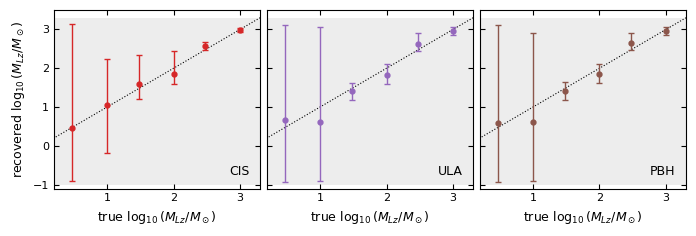

In [4]:
def interval(x, lo=2.275, hi=97.725):
    # median and the central 2-sigma (95.4%) credible interval
    return np.percentile(x, [lo, 50, hi])


truth = np.log10(MASSES)
with plt.rc_context(PUB):
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.4), sharey=True)
    for ax, (lens, (_, _, color)) in zip(axes, LENSES.items()):
        q = np.array([interval(np.log10(samples[lens, M]['MLz'])) for M in MASSES])
        ax.axhspan(np.log10(0.1), np.log10(2000), color='0.93', lw=0, zorder=0)
        ax.plot([0, 3.3], [0, 3.3], 'k:', lw=0.8)
        ax.errorbar(truth, q[:, 1], yerr=[q[:, 1] - q[:, 0], q[:, 2] - q[:, 1]], fmt='o', ms=3.5, color=color,
                    capsize=2, elinewidth=1)
        ax.set(xlabel=r'true $\log_{10}(M_{Lz}/M_\odot)$', xlim=(0.2, 3.3), ylim=(-1.1, 3.5))
        ax.text(0.95, 0.06, lens, transform=ax.transAxes, ha='right', va='bottom', fontsize=9)
    axes[0].set_ylabel(r'recovered $\log_{10}(M_{Lz}/M_\odot)$')
    fig.tight_layout(w_pad=0.6)
    fig.savefig(paths.FIGURES_DIR / 'mass_scan_mlz.png', dpi=300, bbox_inches='tight')
    plt.show()

At $3\,M_\odot$ the mass posterior spans most of the prior for all three lenses. The CIS lens is partly constrained already at $10\,M_\odot$, while the ULA and PBH lenses need about $30\,M_\odot$. Above that, the 2$\sigma$ interval shrinks steadily with mass.

The three lenses share the injection and the noise realization, and at a given mass their medians shift in the same direction: below the truth at $100\,M_\odot$ and above it at $300\,M_\odot$. Shifts that are common to all three lenses are what one expects from a shared noise realization.

## 2. Source position and lens shape

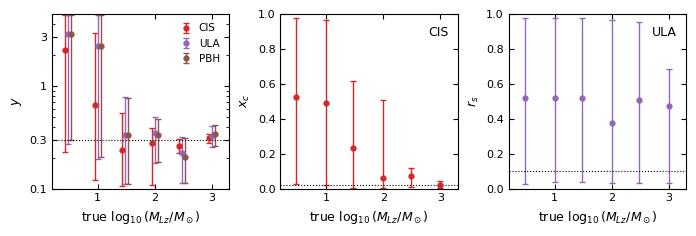

In [5]:
offsets = dict(CIS=-0.05, ULA=0.0, PBH=0.05)
with plt.rc_context(PUB):
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.4))
    for lens, (_, _, color) in LENSES.items():
        q = np.array([interval(samples[lens, M]['y']) for M in MASSES])
        axes[0].errorbar(truth + offsets[lens], q[:, 1], yerr=[q[:, 1] - q[:, 0], q[:, 2] - q[:, 1]],
                         fmt='o', ms=3.5, color=color, capsize=2, elinewidth=1, label=lens)
    axes[0].axhline(Y_TRUE, color='k', lw=0.8, ls=':')
    axes[0].set(ylabel='$y$', yscale='log', ylim=(0.1, 5))
    axes[0].set_yticks([0.1, 0.3, 1, 3]); axes[0].set_yticklabels(['0.1', '0.3', '1', '3'])
    axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
    axes[0].legend(frameon=False, loc='upper right', handletextpad=0.2)

    for ax, lens in zip(axes[1:], ['CIS', 'ULA']):
        shape, label, color = LENSES[lens]
        q = np.array([interval(samples[lens, M]['lp']) for M in MASSES])
        ax.errorbar(truth, q[:, 1], yerr=[q[:, 1] - q[:, 0], q[:, 2] - q[:, 1]], fmt='o', ms=3.5, color=color,
                    capsize=2, elinewidth=1)
        ax.axhline(shape, color='k', lw=0.8, ls=':')
        ax.set(ylabel=label, ylim=(0, 1))
        ax.text(0.95, 0.93, lens, transform=ax.transAxes, ha='right', va='top', fontsize=9)
    for ax in axes:
        ax.set(xlabel=r'true $\log_{10}(M_{Lz}/M_\odot)$', xlim=(0.2, 3.3))
    fig.tight_layout(w_pad=0.8)
    fig.savefig(paths.FIGURES_DIR / 'mass_scan_y_shape.png', dpi=300, bbox_inches='tight')
    plt.show()

- **Source position.** $y$ follows the mass. It fills its prior at $3\,M_\odot$ and is measured to within a few hundredths at $1000\,M_\odot$.
- **CIS core radius.** The data first exclude large cores, from $30$ to $100\,M_\odot$ on, and at $1000\,M_\odot$ the 2$\sigma$ interval brackets the true $x_c = 0.02$.
- **ULA soliton radius.** Unlike the CIS core, $r_s$ stays close to its prior up to $300\,M_\odot$. At $1000\,M_\odot$ the data exclude $r_s \gtrsim 0.7$, but the posterior peaks near $r_s \approx 0.5$, and the true $r_s = 0.1$ lies in its lower tail, inside the 2$\sigma$ interval.

## 3. Marginal posteriors

The same runs as 1D marginal posteriors, coloured by lens mass. Dotted lines mark the injected values. For $M_{Lz}$, the injected value differs between runs, so the panel shows the offset $\log_{10}(M_{Lz}/M_{\rm true})$.

In [6]:
cmap = plt.get_cmap('viridis')
colors = {M: cmap(i / (len(MASSES) - 1)) for i, M in enumerate(MASSES)}

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for row, (lens, (shape, label, _)) in zip(axes, LENSES.items()):
    for M in MASSES:
        s = samples[lens, M]
        kw = dict(bins=40, density=True, histtype='step', lw=1.6, color=colors[M], label=f'{M} $M_\\odot$')
        row[0].hist(np.log10(s['MLz'] / M), range=(-3, 2.5), **kw)
        row[1].hist(s['y'], range=(0.1, 5), **kw)
        if shape is not None:
            row[2].hist(s['lp'], range=(0, 1), **kw)
    row[0].axvline(0, color='k', ls=':')
    row[1].axvline(Y_TRUE, color='k', ls=':')
    row[0].set_ylabel(lens, fontsize=13)
    if shape is None:
        row[2].axis('off')
    else:
        row[2].axvline(shape, color='k', ls=':')
        row[2].set_xlabel(label)
    for ax in row:
        ax.set_yticks([])
axes[2, 0].set_xlabel(r'$\log_{10}(M_{Lz}/M_{\rm true})$')
axes[2, 1].set_xlabel('$y$')
axes[0, 2].legend(frameon=False, fontsize=9)
plt.tight_layout()

## 4. Summary table

For each run: the posterior median, the central 2$\sigma$ (95.4%) interval, and the ratio of the interval width to the prior width. A ratio near 0.95 means the parameter is prior-dominated, and smaller values mean the data constrain it. $M_{Lz}$ is in $\log_{10}$, with a prior width of $\log_{10}(2000/0.1) = 4.3$.

In [7]:
PRIOR_WIDTH = {'log10 M_Lz': np.log10(2000 / 0.1), 'y': 4.9, 'shape': {'CIS': 1.0, 'ULA': 0.99}}

rows = []
for (lens, M), s in samples.items():
    params = {'log10 M_Lz': np.log10(s['MLz']), 'y': s['y']}
    if LENSES[lens][0] is not None:
        params['shape'] = s['lp']
    for name, x in params.items():
        lo, med, hi = interval(x)
        width = PRIOR_WIDTH[name][lens] if name == 'shape' else PRIOR_WIDTH[name]
        rows.append(dict(lens=lens, M_Lz=M, parameter=name, median=med, lo_2sigma=lo, hi_2sigma=hi,
                         prior_fraction=(hi - lo) / width))
table = pd.DataFrame(rows)
table.pivot_table(index=['lens', 'M_Lz'], columns='parameter', values='prior_fraction', sort=False).style.format(precision=2)

In [8]:
table.style.format(precision=3).hide(axis='index')

lens,M_Lz,parameter,median,lo_2sigma,hi_2sigma,prior_fraction
CIS,3,log10 M_Lz,0.456,-0.897,3.144,0.940
CIS,3,y,2.239,0.227,4.855,0.945
CIS,3,shape,0.527,0.025,0.979,0.954
CIS,10,log10 M_Lz,1.043,-0.172,2.241,0.561
CIS,10,y,0.649,0.121,3.292,0.647
CIS,10,shape,0.493,0.021,0.968,0.946
CIS,30,log10 M_Lz,1.585,1.215,2.343,0.262
CIS,30,y,0.239,0.105,0.545,0.090
CIS,30,shape,0.234,0.006,0.616,0.611
CIS,100,log10 M_Lz,1.849,1.602,2.432,0.193


## Takeaways

- **The lens mass sets what can be learned.** Below $M_{Lz} \approx 10$ to $30\,M_\odot$, the LIGO band sits at $w < 1$ and the data barely distinguish a lensed from an unlensed signal. Above it, the mass and source position are recovered, with uncertainties that shrink as $M_{Lz}$ grows.
- **Lens shapes are harder.** The CIS core radius becomes measurable only at the highest masses in the scan. The ULA soliton radius remains poorly constrained even at $1000\,M_\odot$.
- **The point lens and the ULA soliton look alike.** They give nearly identical mass and position posteriors at every mass. Together with the unconstrained $r_s$, this is consistent with a soliton of $r_s = 0.1$ lensing these frequencies much like a point mass.